# Primera etapa: Exploracion de los datos

## 00.Exportación y procesamiento de los datos


In [13]:
# Librerias

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import os

#### 001. Fusionar celdas (Sólo se ejecuta una vez)

In [14]:
# Proceso de exportacion de los datos

# 1. Rutas de carga según la arquitectura Cookiecutter
RAW_DIR = "../data/raw/"
PROCESSED_DIR = "../data/processed/"

# Carga de datos
print("Cargando datos crudos...")
df_transaction = pd.read_csv(os.path.join(RAW_DIR, "train_transaction.csv"))
df_identity = pd.read_csv(os.path.join(RAW_DIR, "train_identity.csv"))

Cargando datos crudos...


In [15]:
# Fusión mediante Left Join
df = pd.merge(df_transaction, df_identity, on='TransactionID', how='left')
print(f"Fusión completada. Dimensiones totales: {df.shape}")
# Exportar datos unidos para el siguiente notebook
# Se recomienda formato parquet por velocidad y eficiencia de almacenamiento
df.to_parquet(os.path.join(PROCESSED_DIR, "train_merged.parquet"))

Fusión completada. Dimensiones totales: (590540, 434)


### SetUp

In [16]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent          # notebooks/ -> raíz del proyecto
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_processed, column_groups, FIGURES_DIR, TARGET, ID_COL, TIME_COL

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
df = load_processed()    # lee data/processed/train_merged.parquet
groups = column_groups(df)
print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
{k: len(v) for k, v in groups.items()}

(590540, 435) 1.14 GB


{'card': 6,
 'addr': 2,
 'dist': 2,
 'email': 2,
 'C': 14,
 'D': 15,
 'M': 9,
 'V': 339,
 'id': 38,
 'device': 2}

In [18]:
df.head(20)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,has_identity
0,2987000,0,86400,68.500000,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2987001,0,86401,29.000000,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2987002,0,86469,59.000000,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,2987003,0,86499,50.000000,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,2987004,0,86506,50.000000,H,4497,514.0,150.0,mastercard,102.0,...,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,1
5,2987005,0,86510,49.000000,W,5937,555.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
6,2987006,0,86522,159.000000,W,12308,360.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
7,2987007,0,86529,422.500000,W,12695,490.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
8,2987008,0,86535,15.000000,H,2803,100.0,150.0,visa,226.0,...,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device,1
9,2987009,0,86536,117.000000,W,17399,111.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


### Análisis de variables (Glosario)

* **C1 a C14 (números de teléfono, direcciones de correo electrónico, o tarjetas de pago asociadas):** Representan la cantidad de veces que ciertas entidades, aparecen ligadas a un usuario u operación específica, aunque su significado exacto está ofuscado por Vesta Corporation

* **id (Identificadores):** anotaciones que se hacen para distinguir especificamente de que usuario se esta hablando


* **D1 - D15 (Distancias temporales):** Representan Timedeltas o deltas de tiempo, indicando métricas como los días transcurridos entre transacciones pasadas y la actual.

* **V1 - V339 (Vesta Rich Features):** Es un conjunto masivo de variables continuas diseñadas por Vesta. Son características avanzadas precomputadas que incluyen clasificaciones, conteos de perfil y relaciones complejas entre distintas entidades de pago.

* **M1 - M9 (Match):** Variables de coincidencia (generalmente booleanas o categóricas) que indican si ciertos datos concuerdan, como si el nombre en la tarjeta coincide exactamente con el nombre en la dirección de facturación del cliente.

* **TransactionDT:** Es un delta de tiempo continuo expresado en segundos a partir de una fecha de referencia base (no es un timestamp tradicional).

* **TransactionAmt:** El importe o cantidad de dinero de la transacción en dólares (USD).

* **ProductCD:** El código del producto, que categoriza el tipo de bien o servicio adquirido.

* **card1 - card6:** Información intrínseca de la tarjeta, anonimizada y categorizada, que abarca el tipo de tarjeta (débito/crédito), el nivel de la cuenta, el banco emisor y el país de origen.

* **addr1, addr2:** Representan las regiones de la dirección de facturación, usualmente correspondientes al código postal (zona) y al país.

* **P_emaildomain / R_emaildomain:** Dominios de correo electrónico del comprador (Purchaser) y del receptor/vendedor (Recipient).

* **DeviceType / DeviceInfo:** Variables del archivo de identidad que indican el tipo de dispositivo y la información del modelo o navegador utilizado

## 01.Análisis Estructural 
**Pregunta:** ¿Qué tan completa, diversa y estructuralmente consistente es nuestra información?

### Faltantes por columna

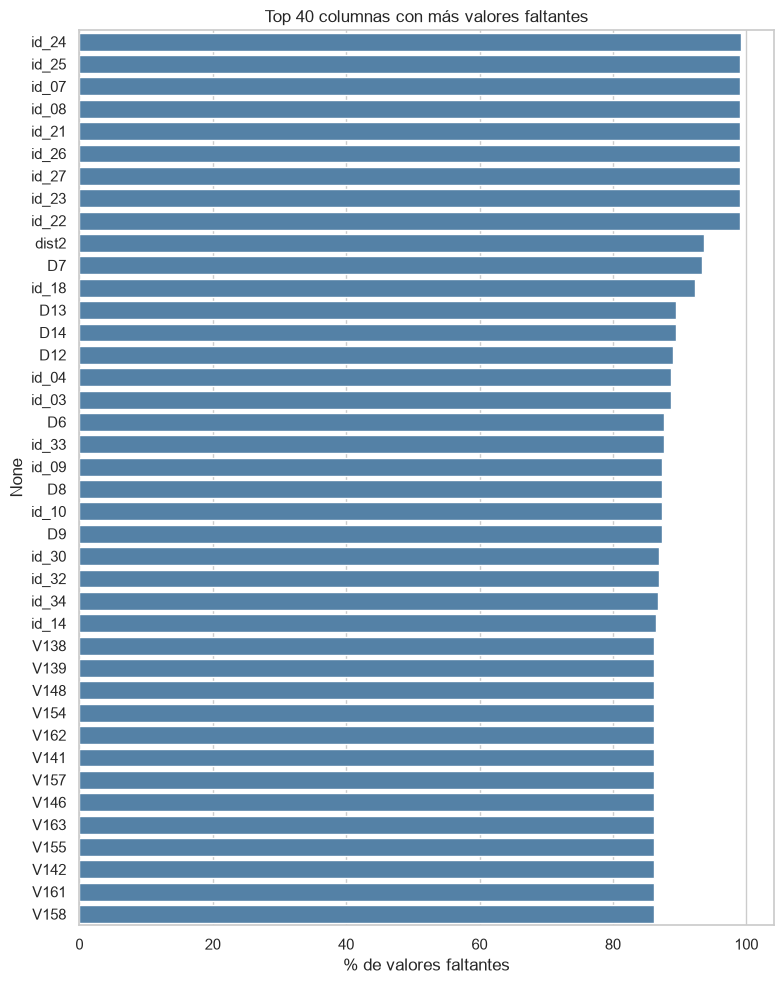

id        84.8
device    78.0
dist      76.6
D         58.2
M         49.9
email     46.4
V         43.0
addr      11.1
card       0.5
C          0.0
dtype: float64

In [19]:
missing_pct = df.isna().mean().mul(100).sort_values(ascending=False)

top = missing_pct.head(40)
fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(x=top.values, y=top.index, color="steelblue", ax=ax)
ax.set_xlabel("% de valores faltantes")
ax.set_title("Top 40 columnas con más valores faltantes")
save_fig("01_missing_by_column")

# Con 434 columnas el top 40 se ve casi plano; este resumen por familia es más informativo
pd.Series({k: df[v].isna().mean().mean() * 100 for k, v in groups.items() if v}).round(1).sort_values(ascending=False)

### Histograma de faltantes

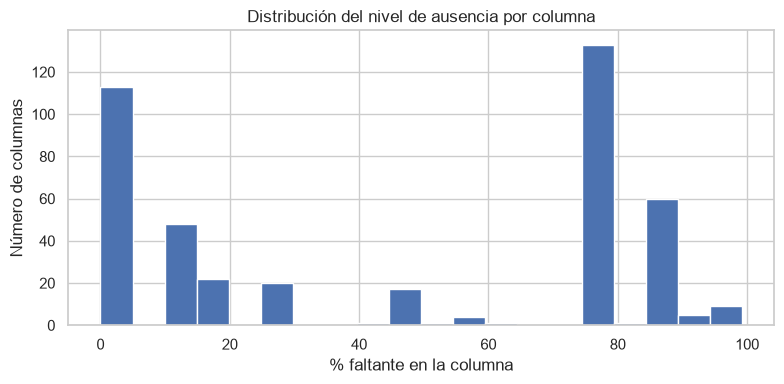

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(missing_pct, bins=20, edgecolor="white")
ax.set_xlabel("% faltante en la columna")
ax.set_ylabel("Número de columnas")
ax.set_title("Distribución del nivel de ausencia por columna")
save_fig("02_missing_histogram")

### Cardinalidad 


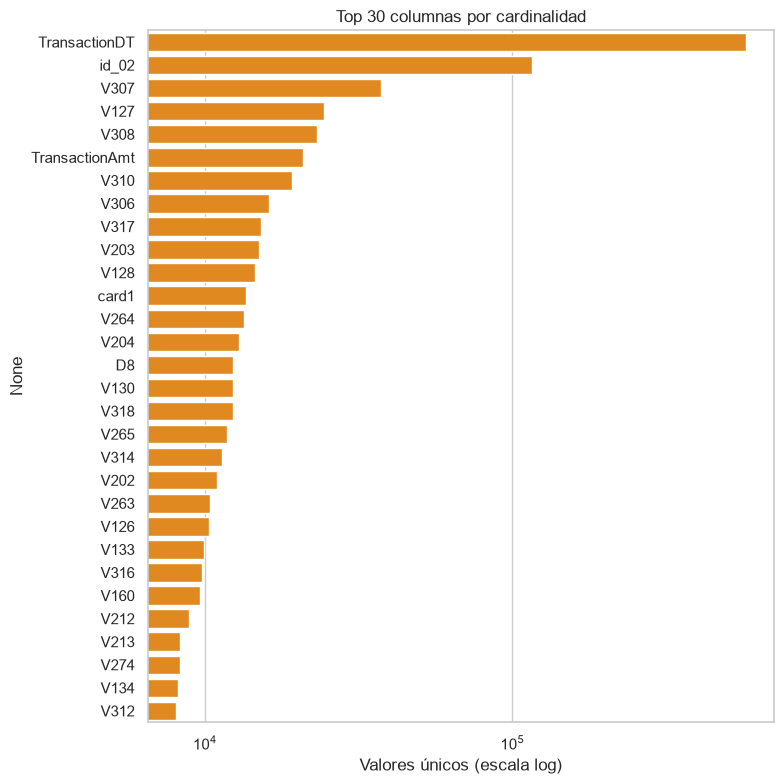

1 (constante)      0
2                 27
3-10              93
11-50            118
51-1000          106
>1000             90
Name: count, dtype: int64

In [21]:
nunique = df.drop(columns=[ID_COL]).nunique().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))
top = nunique.head(30)
sns.barplot(x=top.values, y=top.index, color="darkorange", ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Valores únicos (escala log)")
ax.set_title("Top 30 columnas por cardinalidad")
save_fig("03_cardinality")

# Resumen por rangos (constantes y binarias salen aquí)
bins = pd.cut(nunique, [0, 1, 2, 10, 50, 1000, np.inf],
              labels=["1 (constante)", "2", "3-10", "11-50", "51-1000", ">1000"])
bins.value_counts().sort_index()

### Duplicados 

In [22]:
pd.DataFrame({
    "duplicados": {
        "TransactionID repetido": df[ID_COL].duplicated().sum(),
        "Filas idénticas (sin TransactionID)": df.drop(columns=[ID_COL]).duplicated().sum(),
    }
})

,duplicados
TransactionID repetido,0
Filas idénticas (sin TransactionID),3


### Tipos de variables

In [23]:
# Numéricas que en realidad son códigos categóricos. Después esta lista pasa a configs/default.yaml
CAT_NUMERIC = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

def var_type(col):
    if col == TARGET:        return "objetivo"
    if col == ID_COL:        return "identificador"
    if col == TIME_COL:      return "temporal"
    if col == "has_identity": return "binaria derivada"
    if not pd.api.types.is_numeric_dtype(df[col]): return "categórica"
    if col in CAT_NUMERIC:   return "categórica (codificada)"
    return "numérica"

types = pd.Series({c: var_type(c) for c in df.columns})
summary = pd.DataFrame({"tipo": types, "n_unique": nunique, "pct_nulos": missing_pct.round(1)})

print(types.value_counts())
cat_cols = types[types.str.startswith("categórica")].index.tolist()
num_cols = types[types == "numérica"].index.tolist()
print(len(cat_cols), "categóricas |", len(num_cols), "numéricas")

numérica                   394
categórica                  31
categórica (codificada)      6
identificador                1
objetivo                     1
temporal                     1
binaria derivada             1
Name: count, dtype: int64
37 categóricas | 394 numéricas


In [24]:
# A2: ¿el pico de ~76% de nulos viene del left join?
print(f"Transacciones con registro de identidad: {df['has_identity'].mean():.1%}")

# A8: las 3 filas idénticas, ¿tienen la misma etiqueta?
dups = df[df.drop(columns=[ID_COL]).duplicated(keep=False)]
display(dups[[ID_COL, TIME_COL, "TransactionAmt", TARGET]])

# A9: constantes y conteo por tipo
print("Columnas constantes:", nunique[nunique <= 1].index.tolist())
print(types.value_counts())

Transacciones con registro de identidad: 24.4%


,TransactionID,TransactionDT,TransactionAmt,isFraud
295456,3282456,7310775,47.950001,0
295457,3282457,7310775,47.950001,0
453414,3440414,11576951,512.950012,0
453415,3440415,11576951,512.950012,0
570433,3557433,15129302,44.000000,0
570434,3557434,15129302,44.000000,0


Columnas constantes: []
numérica                   394
categórica                  31
categórica (codificada)      6
identificador                1
objetivo                     1
temporal                     1
binaria derivada             1
Name: count, dtype: int64


## 02. Distribución de la variable objetivo
**Pregunta:** ¿Qué tan desbalanceado está nuestro problema de clasificación?

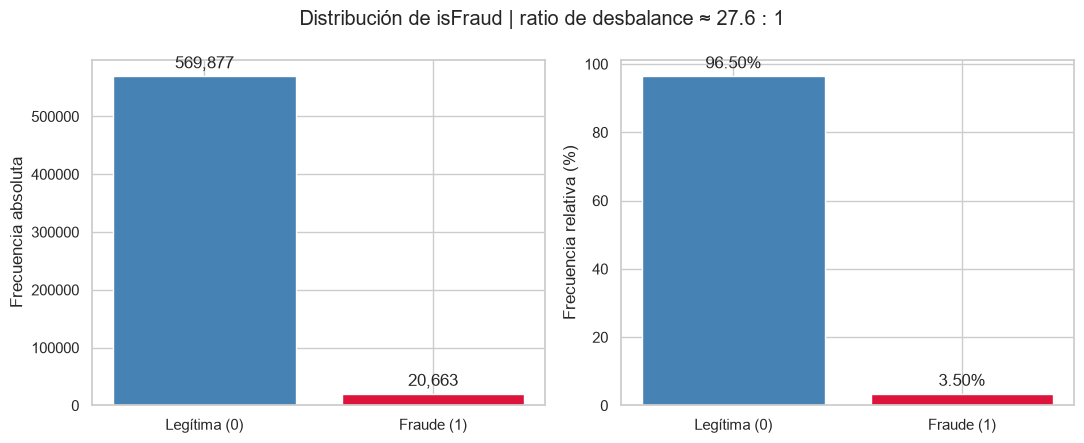

In [25]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100
ratio = counts[0] / counts[1]
labels = ["Legítima (0)", "Fraude (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, vals, fmt, ylab in [(axes[0], counts, "{:,.0f}", "Frecuencia absoluta"),
                            (axes[1], pct, "{:.2f}%", "Frecuencia relativa (%)")]:
    bars = ax.bar(labels, vals.values, color=["steelblue", "crimson"])
    ax.bar_label(bars, labels=[fmt.format(v) for v in vals.values], padding=3)
    ax.set_ylabel(ylab)
fig.suptitle(f"Distribución de isFraud | ratio de desbalance ≈ {ratio:.1f} : 1")
save_fig("04_class_balance")

## 03. Análisis de importes de transacción
**Pregunta:** ¿El comportamiento económico de una transacción fraudulenta es diferente al de una legítima?



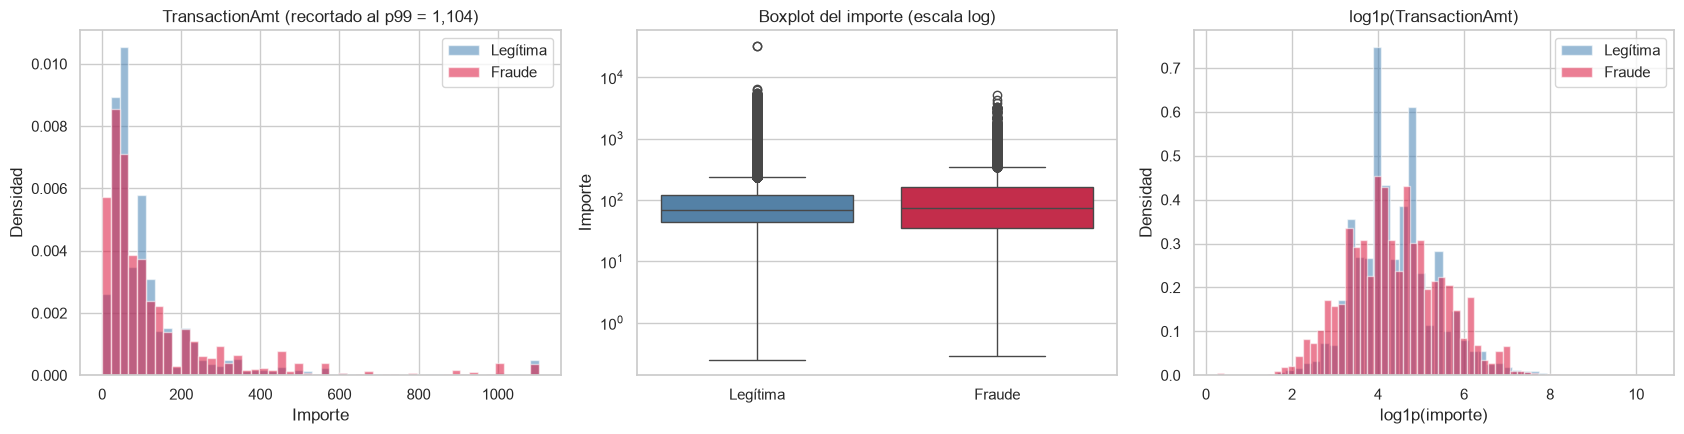

,count,mean,std,min,25%,50%,75%,95%,99%,max
isFraud,,,,,,,,,,
0,569877.0,134.51,239.40,0.25,43.97,68.5,120.0,435.0,1104.0,31937.39
1,20663.0,149.24,232.21,0.29,35.04,75.0,161.0,500.0,994.0,5191.00


In [26]:
amt = df[["TransactionAmt", TARGET]].copy()
amt["log_amt"] = np.log1p(amt["TransactionAmt"])
cap = amt["TransactionAmt"].quantile(0.99)   # recorte solo para visualizar
colors = {0: "steelblue", 1: "crimson"}
names = {0: "Legítima", 1: "Fraude"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Histograma por clase (density=True porque las clases están desbalanceadas)
for k in (0, 1):
    axes[0].hist(amt.loc[amt[TARGET] == k, "TransactionAmt"].clip(upper=cap),
                 bins=50, alpha=0.55, density=True, color=colors[k], label=names[k])
axes[0].set(title=f"TransactionAmt (recortado al p99 = {cap:,.0f})", xlabel="Importe", ylabel="Densidad")
axes[0].legend()

# 2) Boxplot por clase (escala log por la cola larga)
sns.boxplot(data=amt, x=TARGET, y="TransactionAmt", hue=TARGET, palette=colors,
            legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_xticks([0, 1], [names[0], names[1]])
axes[1].set(title="Boxplot del importe (escala log)", xlabel="", ylabel="Importe")

# 3) log1p(TransactionAmt) por clase
for k in (0, 1):
    axes[2].hist(amt.loc[amt[TARGET] == k, "log_amt"],
                 bins=50, alpha=0.55, density=True, color=colors[k], label=names[k])
axes[2].set(title="log1p(TransactionAmt)", xlabel="log1p(importe)", ylabel="Densidad")
axes[2].legend()
save_fig("05_amount_by_class")

amt.groupby(TARGET)["TransactionAmt"].describe(percentiles=[.25, .5, .75, .95, .99]).round(2)

## 04. Análisis temporal del fraude
**Pregunta:** ¿El comportamiento del fraude cambia con el tiempo?

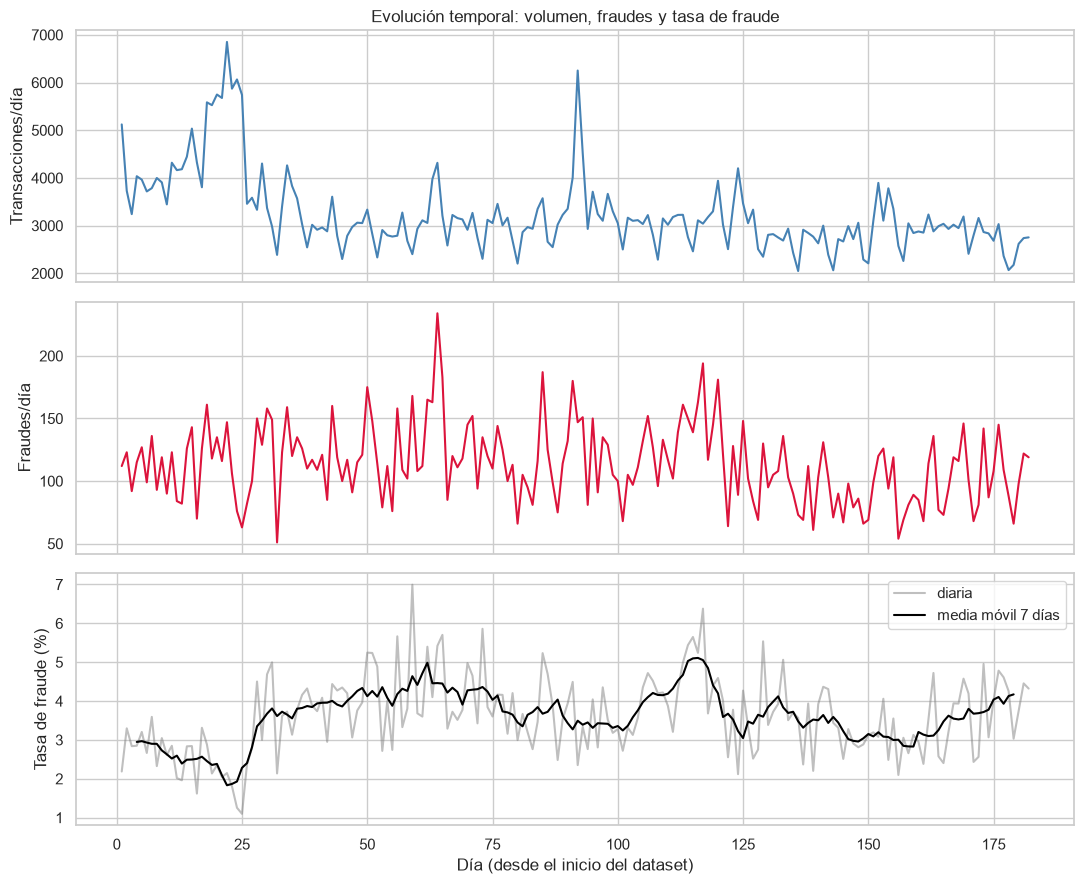

In [27]:
t = df[[TIME_COL, TARGET]].copy()
t["day"] = (t[TIME_COL] // 86400).astype(int)
daily = t.groupby("day")[TARGET].agg(n_tx="size", n_fraud="sum")
daily["fraud_rate"] = daily["n_fraud"] / daily["n_tx"] * 100

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axes[0].plot(daily.index, daily["n_tx"], color="steelblue")
axes[0].set_ylabel("Transacciones/día")
axes[1].plot(daily.index, daily["n_fraud"], color="crimson")
axes[1].set_ylabel("Fraudes/día")
axes[2].plot(daily.index, daily["fraud_rate"], color="gray", alpha=0.5, label="diaria")
axes[2].plot(daily.index, daily["fraud_rate"].rolling(7, center=True).mean(),
             color="black", label="media móvil 7 días")
axes[2].set(ylabel="Tasa de fraude (%)", xlabel="Día (desde el inicio del dataset)")
axes[2].legend()
axes[0].set_title("Evolución temporal: volumen, fraudes y tasa de fraude")
save_fig("06_temporal_evolution")

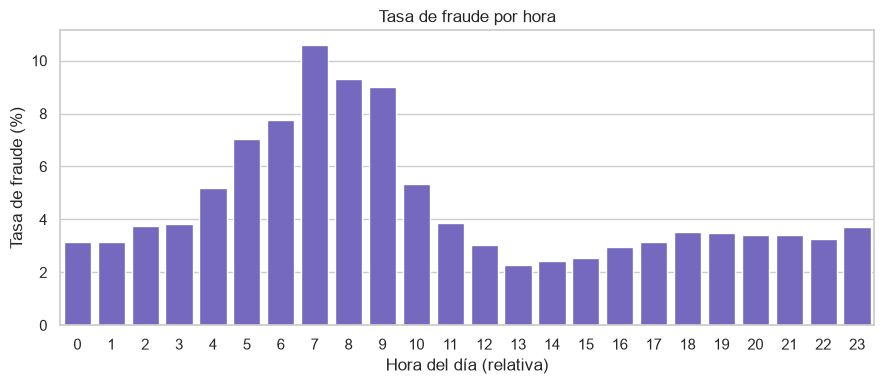

In [28]:
t["hour"] = (t[TIME_COL] // 3600 % 24).astype(int)
by_hour = t.groupby("hour")[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=by_hour.index, y=by_hour.values, color="slateblue", ax=ax)
ax.set(xlabel="Hora del día (relativa)", ylabel="Tasa de fraude (%)",
       title="Tasa de fraude por hora")
save_fig("07_fraud_rate_by_hour")

## 05. Análisis de variables numéricas por clase
**Pregunta:** ¿Qué características numéricas presentan comportamientos diferentes entre operaciones legítimas y fraudulentas?

### Ranking y estadísticas

In [29]:
g = df.groupby(TARGET)[num_cols]
mean, med, std = g.mean().T, g.median().T, g.std().T

effect = pd.DataFrame({"media_0": mean[0], "media_1": mean[1],
                       "mediana_0": med[0], "mediana_1": med[1]})
pooled = np.sqrt((std[0] ** 2 + std[1] ** 2) / 2)
effect["d_cohen"] = (mean[1] - mean[0]) / pooled
effect = effect.reindex(effect["d_cohen"].abs().sort_values(ascending=False).index)
display(effect.head(15).round(3))

# Estadísticas completas por clase (media, std, min, p25, mediana, p75, max) de las 15 con mayor efecto
top_num = effect.head(15).index.tolist()
df.groupby(TARGET)[top_num].describe().T.round(3)

,media_0,media_1,mediana_0,mediana_1,d_cohen
V94,0.125,0.489,0.0,0.0,0.860
V51,0.154,0.647,0.0,1.0,0.855
V50,0.152,0.520,0.0,1.0,0.842
V33,0.119,0.471,0.0,0.0,0.812
V52,0.163,0.738,0.0,1.0,0.809
V34,0.127,0.490,0.0,0.0,0.804
V42,0.142,0.540,0.0,0.0,0.802
V48,0.394,0.072,0.0,0.0,-0.781
V15,0.111,0.445,0.0,0.0,0.778
V79,0.123,0.538,0.0,0.0,0.775


isFraud             0          1
V94 count  484989.000  16387.000
    mean        0.125      0.489
    std         0.331      0.500
    min         0.000      0.000
    25%         0.000      0.000
...               ...        ...
V74 min         0.000      0.000
    25%         0.000      0.000
    50%         0.000      0.000
    75%         0.000      1.000
    max         7.000      8.000

[120 rows x 2 columns]

### Distribuciones de las 6 con mayor efecto

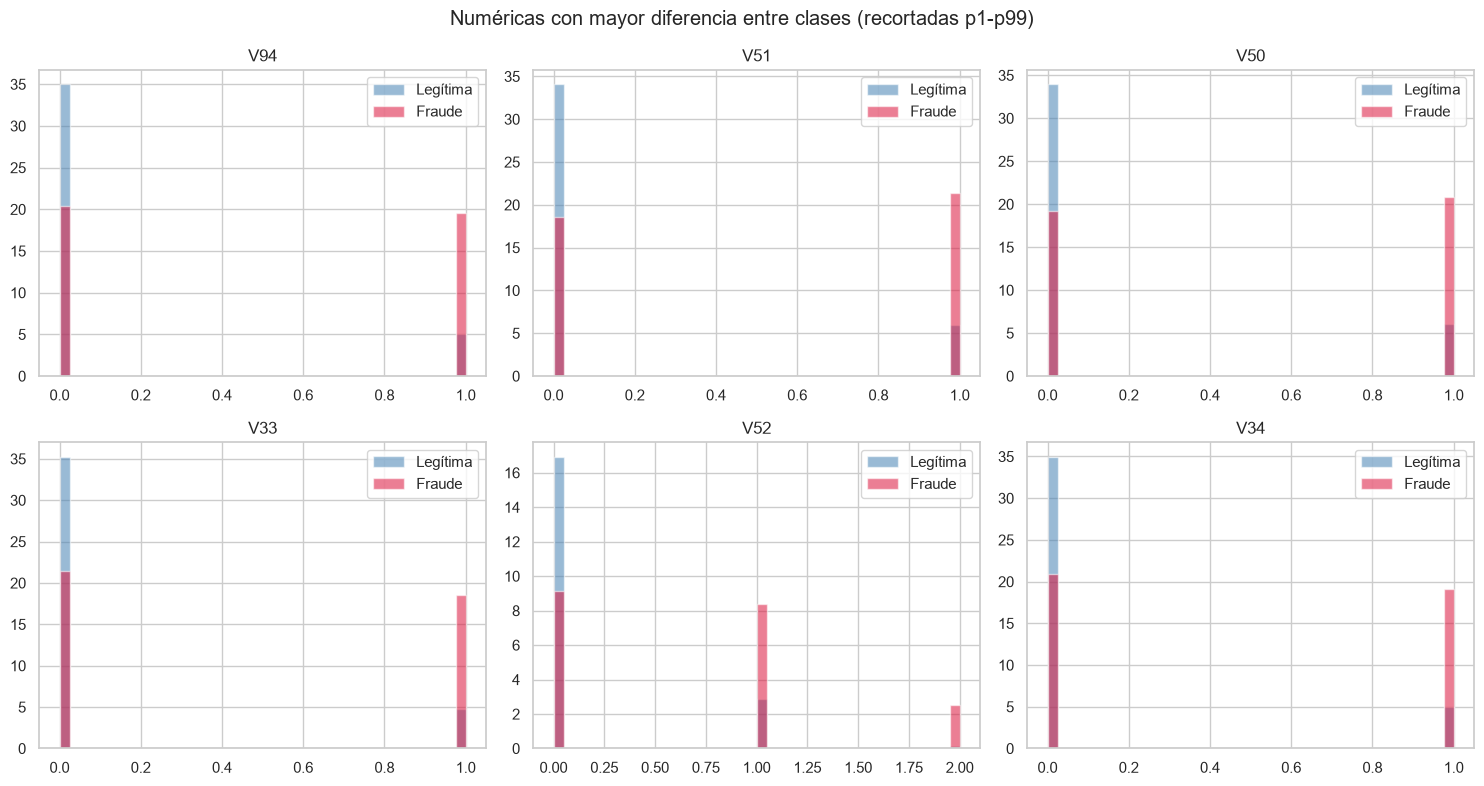

In [30]:
top6 = effect.head(6).index
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), top6):
    lo, hi = df[col].quantile([0.01, 0.99])      # recorte solo visual
    for k in (0, 1):
        x = df.loc[df[TARGET] == k, col].dropna().clip(lo, hi)
        ax.hist(x, bins=40, alpha=0.55, density=True, color=colors[k], label=names[k])
    ax.set_title(col)
    ax.legend()
fig.suptitle("Numéricas con mayor diferencia entre clases (recortadas p1-p99)")
save_fig("08_numeric_top_by_class")

## 06.Análisis de variables categóricas
**Pregunta:** ¿Existen categorías o características que presenten diferentes tasas de fraude?

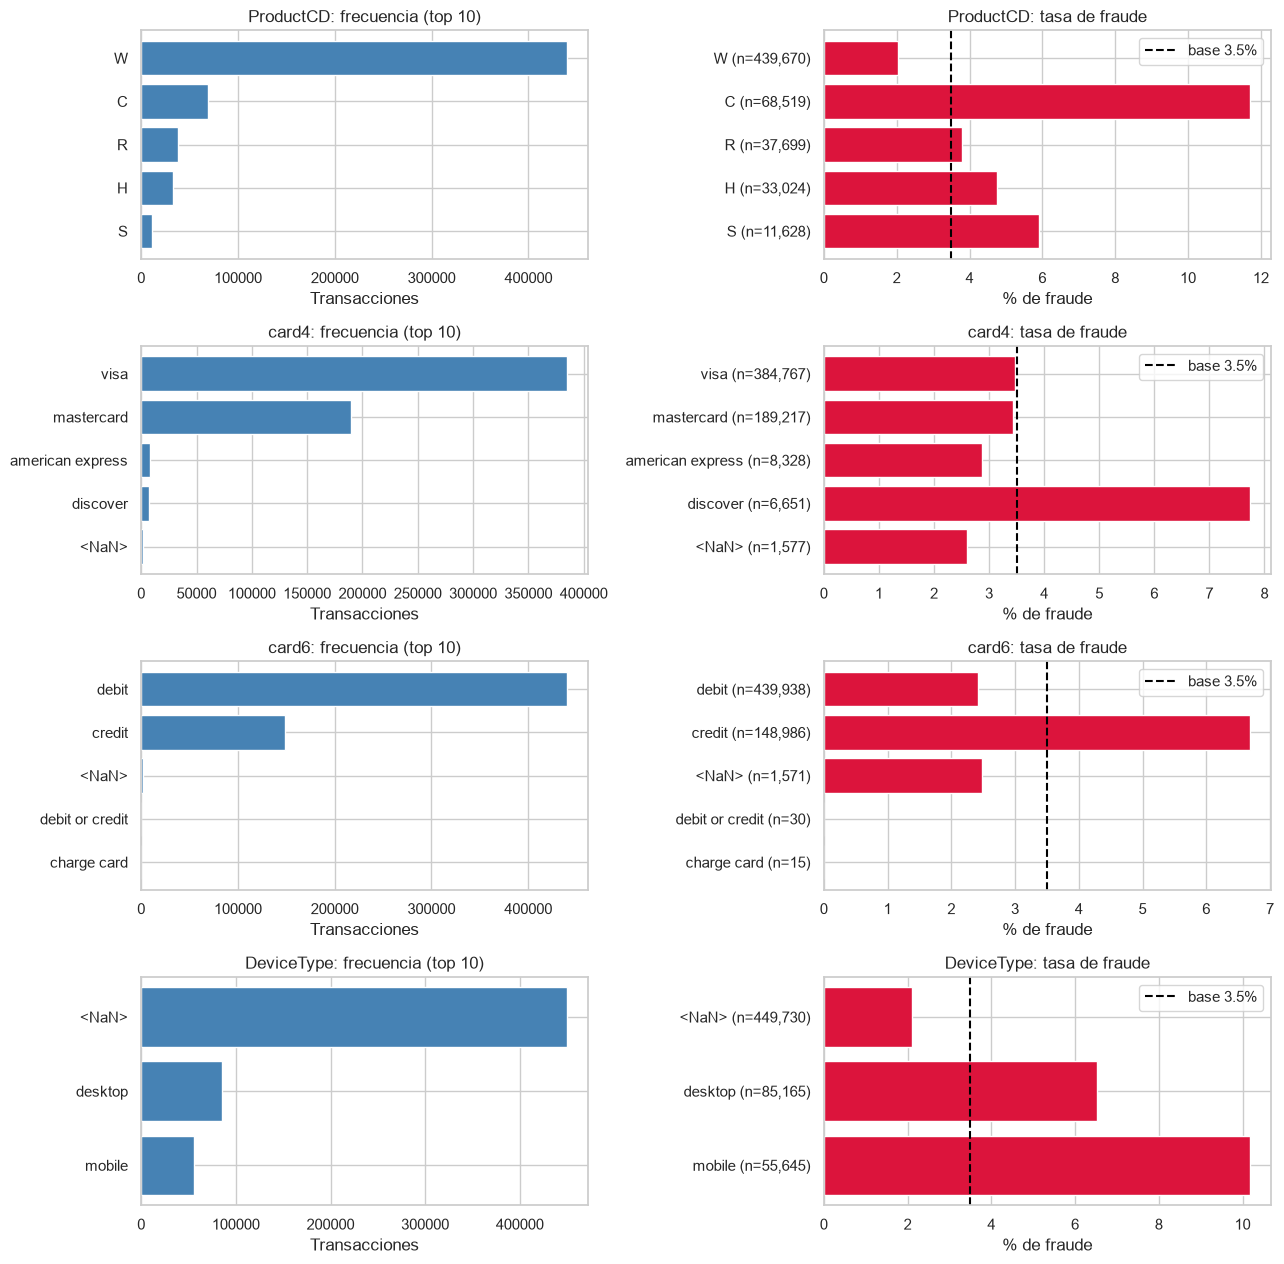

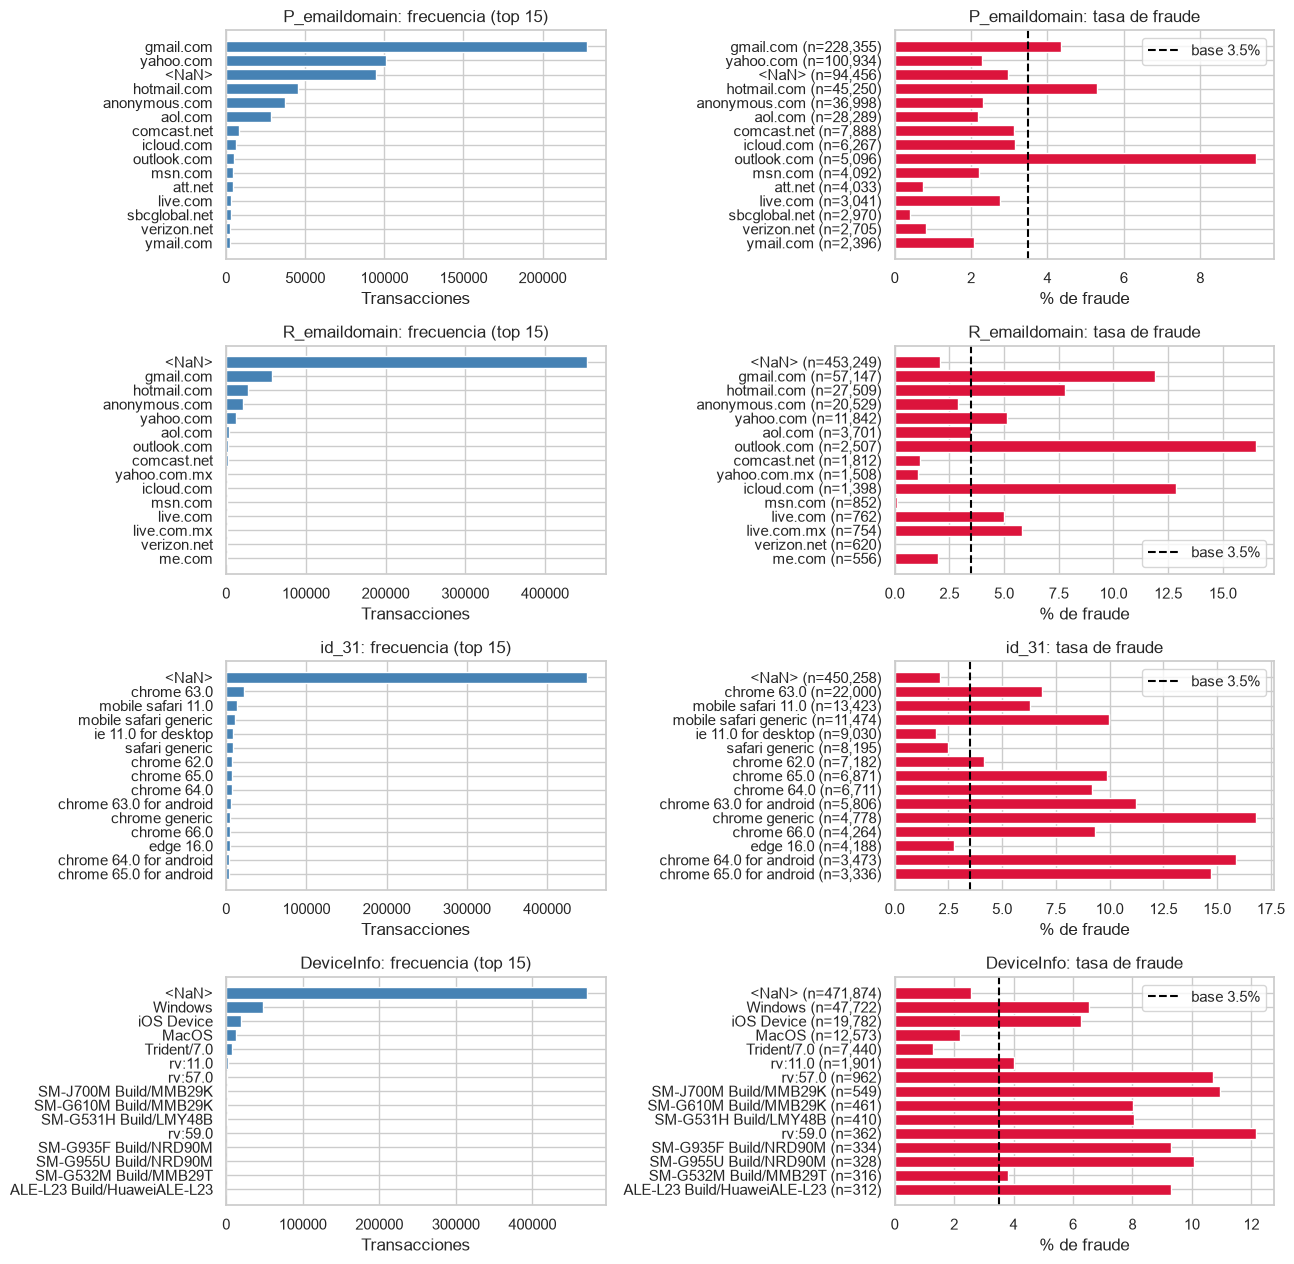

In [31]:
BASE_RATE = df[TARGET].mean() * 100

def cat_panel(cols, top=10, fname=None):
    fig, axes = plt.subplots(len(cols), 2, figsize=(13, 3.2 * len(cols)))
    axes = np.atleast_2d(axes)
    for i, col in enumerate(cols):
        s = df[col].astype("string").fillna("<NaN>")
        freq = s.value_counts().head(top)
        rate = df[TARGET].groupby(s).mean().loc[freq.index] * 100

        axes[i, 0].barh(freq.index.astype(str), freq.values, color="steelblue")
        axes[i, 0].set(title=f"{col}: frecuencia (top {top})", xlabel="Transacciones")

        labels = [f"{c} (n={n:,})" for c, n in freq.items()]   # n visible: tasas con pocos casos son ruidosas
        axes[i, 1].barh(labels, rate.values, color="crimson")
        axes[i, 1].axvline(BASE_RATE, color="black", ls="--", label=f"base {BASE_RATE:.1f}%")
        axes[i, 1].set(title=f"{col}: tasa de fraude", xlabel="% de fraude")
        axes[i, 1].legend()
        for ax in axes[i]:
            ax.invert_yaxis()
    save_fig(fname)

cat_panel(["ProductCD", "card4", "card6", "DeviceType"], top=10, fname="09_cat_main")
cat_panel(["P_emaildomain", "R_emaildomain", "id_31", "DeviceInfo"], top=15, fname="10_cat_high_card")

,variable,n_categorias,chi2,p_valor,cramers_v
1,card1,13553,72289.3260,0.0,0.3154
36,DeviceInfo,1787,44513.7690,0.0,0.2690
2,card2,501,30730.4041,0.0,0.2263
28,id_31,131,20807.5134,0.0,0.1871
10,R_emaildomain,61,19758.2202,0.0,0.1826
3,card3,115,17875.4132,0.0,0.1734
7,addr1,333,17832.7988,0.0,0.1721
31,id_35,3,17183.1133,0.0,0.1706
8,addr2,75,16929.6213,0.0,0.1689
0,ProductCD,5,16742.1715,0.0,0.1684


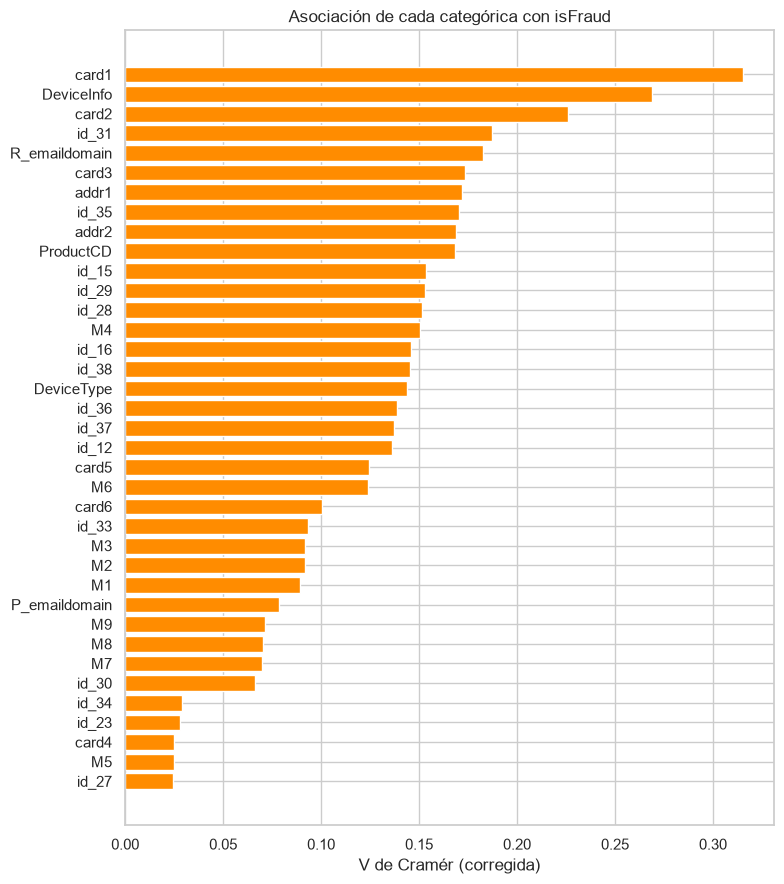

In [32]:
from scipy.stats import chi2_contingency

def cramers_v(col):
    x = df[col].astype("string").fillna("<NaN>")
    ct = pd.crosstab(x, df[TARGET])
    chi2, p, _, _ = chi2_contingency(ct, correction=False)
    n = ct.values.sum()
    r, k = ct.shape
    phi2c = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return {"variable": col, "n_categorias": r, "chi2": chi2, "p_valor": p,
            "cramers_v": np.sqrt(phi2c / min(kc - 1, rc - 1))}

assoc_cat = pd.DataFrame([cramers_v(c) for c in cat_cols]).sort_values("cramers_v", ascending=False)
display(assoc_cat.round(4))

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(assoc_cat["variable"], assoc_cat["cramers_v"], color="darkorange")
ax.invert_yaxis()
ax.set(xlabel="V de Cramér (corregida)", title="Asociación de cada categórica con isFraud")
save_fig("11_cat_association")

## 07.Correlaciones y relaciones entre variables
**Pregunta:** ¿Qué variables presentan relaciones entre sí y cuáles muestran asociación con el fraude?

### Asociación individual con que si es fraude

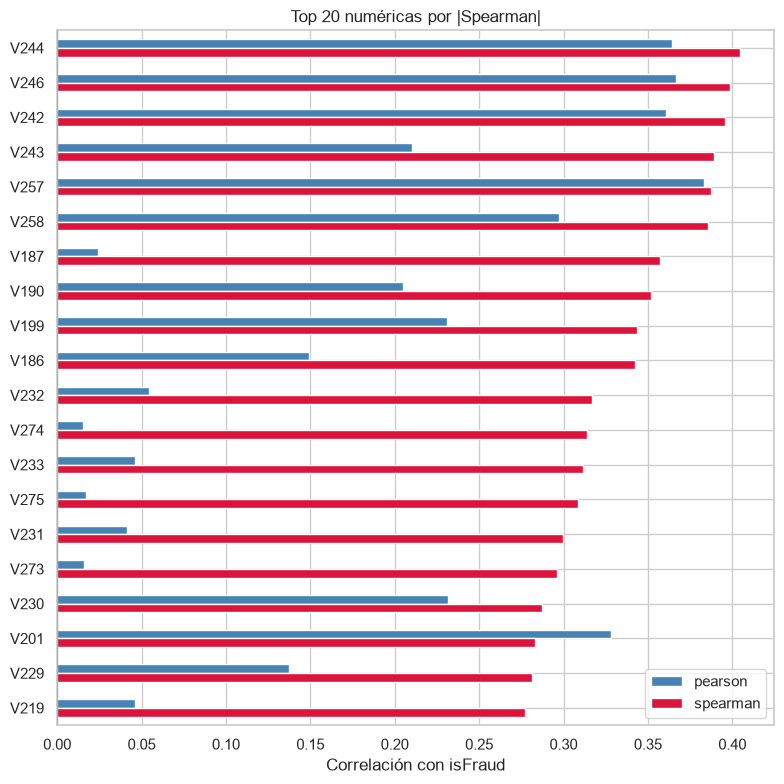

In [33]:
assoc = pd.DataFrame({
    "pearson":  df[num_cols].corrwith(df[TARGET]),
    "spearman": df[num_cols].corrwith(df[TARGET], method="spearman"),
})
top20 = assoc.reindex(assoc["spearman"].abs().sort_values(ascending=False).head(20).index)

fig, ax = plt.subplots(figsize=(8, 8))
top20[["pearson", "spearman"]].plot.barh(ax=ax, color=["steelblue", "crimson"])
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Correlación con isFraud", title="Top 20 numéricas por |Spearman|")
save_fig("12_corr_with_target")

### Heatmap de las 394 numéricas

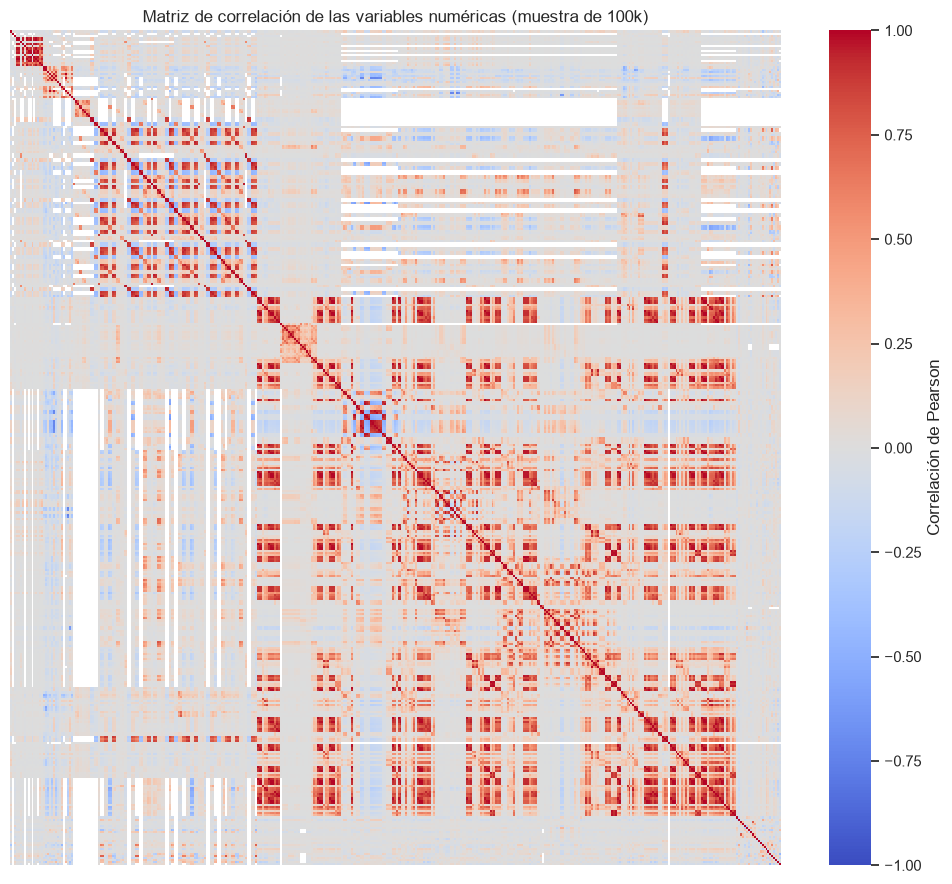

1443 pares con |r| > 0.9; 97% son pares V-V


In [34]:
corr = df[num_cols].sample(100_000, random_state=42).corr()

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False,
            cbar_kws={"label": "Correlación de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación de las variables numéricas (muestra de 100k)")
save_fig("13_corr_matrix_numeric")

# ¿Cuánta redundancia hay?
lower = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
pairs = lower.abs().stack()
pairs = pairs[pairs > 0.9]
vv = np.mean([i.startswith("V") and j.startswith("V") for i, j in pairs.index])
print(f"{len(pairs)} pares con |r| > 0.9; {vv:.0%} son pares V-V")

### Matriz de las más relevantes

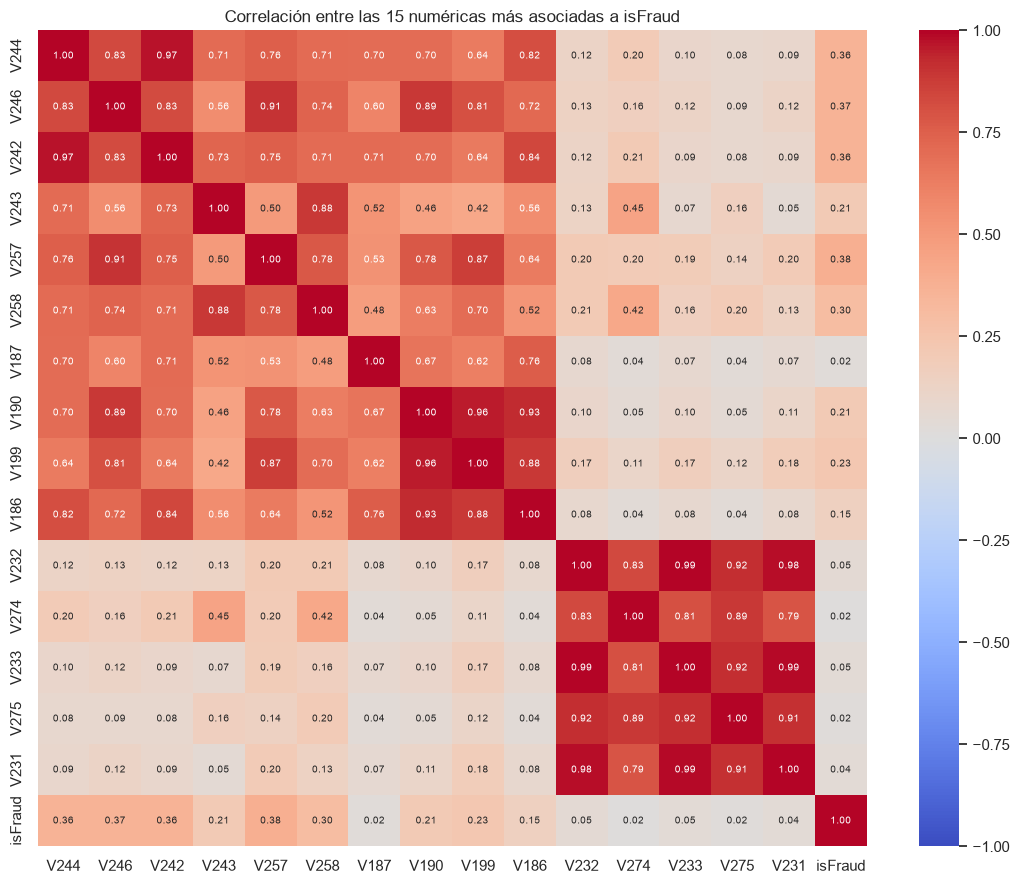

In [35]:
rel = top20.index[:15].tolist()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(df[rel + [TARGET]].corr(), annot=True, fmt=".2f", annot_kws={"size": 7},
            cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación entre las 15 numéricas más asociadas a isFraud")
save_fig("14_corr_top_features")

## 08. Patrones de valores faltantes
**Pregunta:**¿La ausencia de información puede ser un patrón relacionado con el fraude?

### Faltantes por clase

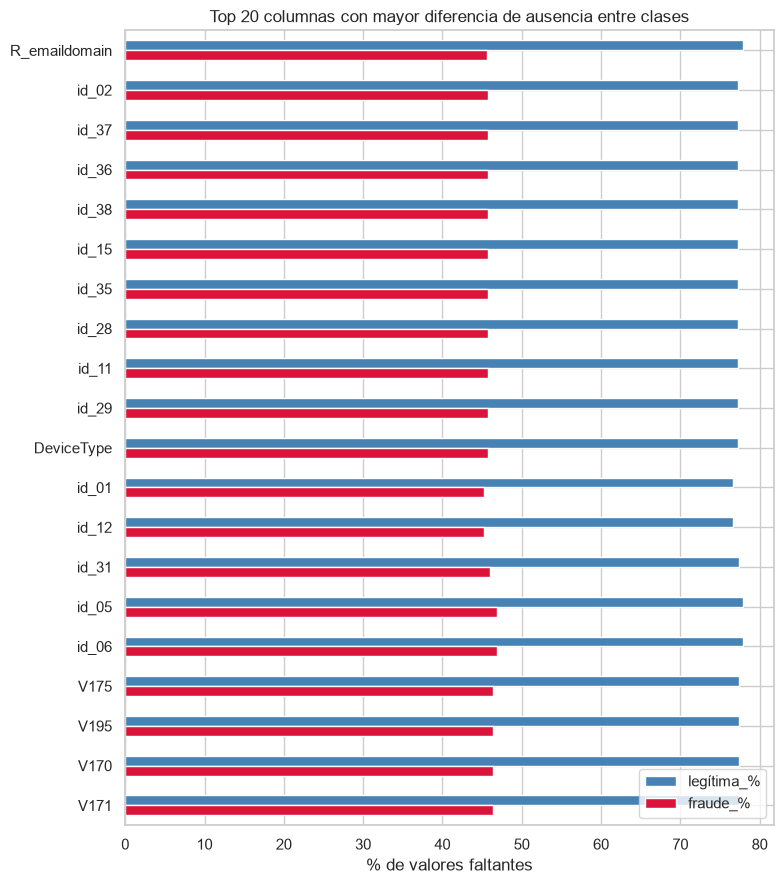

,variable,% nulo,% fraude | nulo,% fraude | presente
0,R_emaildomain,76.75,2.08,8.18
1,id_02,76.15,2.10,7.97
2,id_37,76.13,2.10,7.96
3,id_36,76.13,2.10,7.96
4,id_38,76.13,2.10,7.96
5,id_15,76.13,2.10,7.96
6,id_35,76.13,2.10,7.96
7,id_28,76.13,2.10,7.96
8,id_11,76.13,2.10,7.96
9,id_29,76.13,2.10,7.96


In [36]:
miss_cls = df.drop(columns=[TARGET]).isna().groupby(df[TARGET]).mean().T * 100
miss_cls.columns = ["legítima_%", "fraude_%"]
miss_cls["dif_pp"] = miss_cls["fraude_%"] - miss_cls["legítima_%"]
miss_cls = miss_cls[miss_cls[["legítima_%", "fraude_%"]].max(axis=1) > 0]
miss_cls = miss_cls.reindex(miss_cls["dif_pp"].abs().sort_values(ascending=False).index)

top_miss = miss_cls.head(20)
fig, ax = plt.subplots(figsize=(8, 9))
top_miss[["legítima_%", "fraude_%"]].plot.barh(ax=ax, color=["steelblue", "crimson"])
ax.invert_yaxis()
ax.set(xlabel="% de valores faltantes", ylabel="",
       title="Top 20 columnas con mayor diferencia de ausencia entre clases")
save_fig("15_missing_by_class")

# Indicadores de ausencia (solo para análisis; los definitivos se crean en preprocessing.py)
rows = []
for c in top_miss.index[:15]:
    isn = df[c].isna()
    rows.append({"variable": c, "% nulo": isn.mean() * 100,
                 "% fraude | nulo": df.loc[isn, TARGET].mean() * 100,
                 "% fraude | presente": df.loc[~isn, TARGET].mean() * 100})
display(pd.DataFrame(rows).round(2))

In [37]:
display(df.groupby("has_identity")[TARGET].agg(n="size", tasa_fraude_pct=lambda s: s.mean() * 100).round(2))

# Dentro de las transacciones CON identidad: ¿la ausencia sigue distinguiendo clases?
ident = df[df["has_identity"] == 1]
cols_id = groups["id"] + groups["device"]
within = ident[cols_id].isna().groupby(ident[TARGET]).mean().T * 100
within.columns = ["legítima_%", "fraude_%"]
within["dif_pp"] = within["fraude_%"] - within["legítima_%"]
within.reindex(within["dif_pp"].abs().sort_values(ascending=False).index).head(10).round(1)

,n,tasa_fraude_pct
has_identity,,
0,446307,2.09
1,144233,7.85


,legítima_%,fraude_%,dif_pp
id_14,42.5,68.4,25.9
id_30,44.2,69.6,25.4
id_32,44.2,69.5,25.3
id_34,44.1,69.2,25.1
id_33,47.4,70.3,22.9
id_09,49.5,30.8,-18.7
id_10,49.5,30.8,-18.7
id_04,55.5,37.2,-18.3
id_03,55.5,37.2,-18.3
DeviceInfo,17.2,24.0,6.8


### Ausencias simultáneas

414 columnas con nulos comparten 69 patrones distintos


,n_columnas,familias
0,46,V
1,43,V
2,32,V
3,31,V
4,23,V
5,22,V
6,20,V
7,19,V
8,18,V
9,18,V


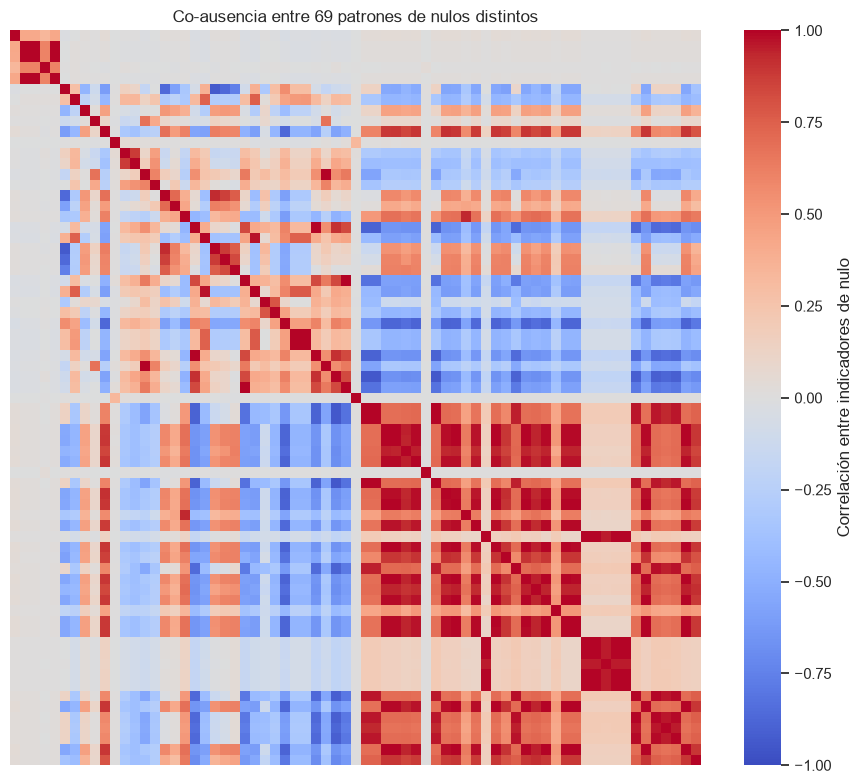

In [38]:
null_cols = [c for c in df.columns if df[c].isna().any()]
pat = pd.Series({c: hash(df[c].isna().to_numpy().tobytes()) for c in null_cols})
fam = {c: k for k, v in groups.items() for c in v}

pat_tab = (pd.DataFrame({"patron": pat, "familia": [fam.get(c, "otra") for c in pat.index]})
           .groupby("patron")
           .agg(n_columnas=("familia", "size"),
                familias=("familia", lambda s: ",".join(sorted(set(s)))))
           .sort_values("n_columnas", ascending=False)
           .reset_index(drop=True))
print(f"{len(null_cols)} columnas con nulos comparten {len(pat_tab)} patrones distintos")
display(pat_tab.head(10))

rep = pat.drop_duplicates().index.tolist()      # una columna por patrón
co = df[rep].sample(100_000, random_state=42).isna().astype("int8").corr()

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(co, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False,
            cbar_kws={"label": "Correlación entre indicadores de nulo"}, ax=ax)
ax.set_title(f"Co-ausencia entre {len(rep)} patrones de nulos distintos")
save_fig("16_comissing_patterns")

## Tabla de decisiones



| # | Hallazgo | Decisión | Dónde se aplica |
|---|---|---|---|
| A1 | Las columnas con más ausencia (~99%) son `id_21`–`id_27`, seguidas de `dist2`, `D7`, `id_18`, `D12`–`D14` (~89–94%) | **No descartar a ciegas.** Conservar un indicador de nulo por columna y decidir el descarte del valor en el Bloque H, según si la ausencia distingue fraude de legítimo | `src/preprocessing.py` (indicadores de nulo), `configs/default.yaml` (`drop_columns`) |
| A2 | La ausencia es bimodal (~113 columnas casi completas, ~133 con ~75-80% de nulos). El **24.4%** de las transacciones tiene registro de identidad, así que el pico de ~76% es **ausencia estructural** del left join | En las familias `id` y `device`, un nulo suele significar "sin registro de identidad", y eso ya lo captura `has_identity`. Los indicadores por columna solo aportan si hay nulos **dentro** de los registros con identidad. Se evalúa en el Bloque H (tasa de nulos con `has_identity == 1`) | `src/preprocessing.py` |
| A3 | Por familia: `id` 84.8%, `device` 78.0%, `dist` 76.6%, `D` 58.2%, `M` 49.9%, `email` 46.4%, `V` 43.0%, `addr` 11.1%, `card` 0.5%, `C` 0.0% | `C` y `card` no necesitan imputación. `id`, `device` y `dist` llevan indicador de nulo. `D`, `M`, `email` y `V` llevan indicador e imputación (mediana para numéricas, categoría "desconocido" para categóricas, calculadas solo con train) | `src/preprocessing.py` (ajustado solo con train) |
| A4 | `TransactionDT` tiene ~590k valores únicos (casi uno por fila) | No usarla cruda como predictor. Se usa para el split temporal y para derivar hora y día | `src/split.py`, `src/preprocessing.py` |
| A5 | `card1` tiene ~13.5k valores únicos y es un código categórico | **No one-hot.** Índices enteros para embeddings en la red y codificación por frecuencia para logística/XGBoost; categorías nuevas en dev/test van a "desconocido" | `src/preprocessing.py`, `configs/default.yaml` (lista de categóricas) |
| A6 | `id_02` (~115k únicos), `D8`, `TransactionAmt` y varias `V` (`V307`, `V127`, `V308`...) tienen cardinalidad alta y parecen continuas | Tratarlas como numéricas (escalado en train; `log1p` para el importe). Se confirma en el Bloque E | `src/preprocessing.py` |
| A7 | `TransactionID` es único (0 repetidos) | Descartar como predictor; solo sirve como llave del join y para el test anti-fuga (sin IDs repetidos entre splits) | `src/preprocessing.py`, `tests/test_no_leakage.py` |
| A8 | Hay **3 pares** de filas idénticas: IDs consecutivos, mismo `TransactionDT` e importe, todas legítimas (3 de 590,540) | **No deduplicar.** Efecto despreciable, misma etiqueta y posiblemente cargos dobles reales. Dejar la nota en el notebook | n/a (nota en el notebook) |
| A9 | 0 columnas constantes. 394 numéricas, 31 categóricas de texto, 6 categóricas codificadas (`card1-3`, `card5`, `addr1-2`). De las numéricas, 93 tienen ≤10 valores únicos (92 `V` y 1 `id`) | **Se quedan numéricas** (banderas y conteos acotados). `cat_cols` = 37 (31 + 6), `num_cols` = 394. Ambas listas pasan a la config | `configs/default.yaml` |
| B1 | 96.5% legítimas vs 3.5% fraude (569,877 vs 20,663); ratio 27.6:1 | Un clasificador al azar tendría PR-AUC ≈ 0.035 (ese es el piso). PR-AUC como métrica principal, pesos de clase o focal loss, **sin sobremuestreo en dev/test** | `src/evaluate.py`, `src/train.py`, `configs/default.yaml` |
| C1 | Medianas similares entre clases (~70-80). El fraude tiene un rango intercuartílico más ancho y más masa en importes bajos. Las legítimas se concentran en importes recurrentes (picos en log1p ≈ 4.0 y ≈ 4.8) | El importe por sí solo discrimina poco. Usar `log1p(TransactionAmt)`. Un indicador de "importe recurrente" queda como hipótesis opcional para Etapa 2, no como decisión | `src/preprocessing.py` |
| C2 | Cola muy larga (p99 = 1,104; máximos ~31k en legítimas y ~5k en fraude) | **No eliminar outliers** (parecen reales en ambas clases). `log1p` más escalado calculado solo con train | `src/preprocessing.py` |
| D1 | Tasa de fraude no estacionaria: ~2-3% en los primeros ~25 días, ~4% después, pico cerca de 5% hacia el día ~115. Picos aislados de volumen (días ~20-25 y ~92) | **Split temporal obligatorio** (sin split aleatorio). Reportar tamaño y tasa de fraude de train/dev/test y avisar de la deriva en la model card | `src/split.py`, `notebooks/02_preprocessing_split.ipynb`, `docs/model_card.md` |
| D2 | La tasa de fraude varía mucho con la hora: pico de ~10.6% en la hora 7, ~7-9% entre las horas 5 y 9, mínimo de ~2.3% hacia las horas 13-14 y ~3-3.7% el resto del día. La hora es **relativa** (el desfase de `TransactionDT` es desconocido) | Derivar hora y día desde `TransactionDT`. La hora es cíclica, así que se codifica con seno/coseno (o como categórica de 24 niveles) y no como un entero lineal. Aclarar en la model card que la hora no corresponde a la hora local real | `src/preprocessing.py`, `docs/model_card.md` |
| E1 | Las 15 numéricas con mayor *d* de Cohen son todas `V` (V94, V51, V50, V33, V52, V34...), banderas o conteos pequeños. En V94 la media es 0.489 en fraude vs 0.125 en legítimas; V48 va al revés (0.072 vs 0.394) | Mantener las `V` como numéricas. No sobreinterpretar la *d*: con este desbalance equivale a r ≈ 0.16. El ranking confiable es el de Spearman (G1) | `src/preprocessing.py` |
| F1 | Tasa de fraude muy por encima de la base (3.5%) en `ProductCD` = C (~11.7% vs ~2% en W), `card6` = credit (6.6% vs 2.4% en debit) y `DeviceType` = mobile (~10%) | Categóricas de baja cardinalidad (`ProductCD`, `card4`, `card6`, `DeviceType`, `M1`-`M9`): one-hot, con "faltante" como categoría propia | `src/preprocessing.py` |
| F2 | La mayor asociación con el fraude está en variables de alta cardinalidad: V de Cramér de `card1` 0.32, `DeviceInfo` 0.27, `card2` 0.23; también `id_31`, `R_emaildomain`, `card3`, `addr1` | Índices enteros para embeddings en la red y codificación por frecuencia para logística/XGBoost. Frecuencia mínima y categoría "desconocido" para raras y nuevas en dev/test | `src/preprocessing.py`, `configs/default.yaml` |
| F3 | V de Cramér < 0.03 en `card4`, `M5`, `id_23`, `id_27`, `id_34` | Candidatas a descartar, **sin decidirlo por Cramér solo** (con categorías raras puede subestimar o inflar). Se confirma con el desempeño en dev | `configs/default.yaml` (`drop_columns`), `notebooks/03_baselines.ipynb` |
| F4 | En `DeviceType`, `DeviceInfo` e `id_31`, la categoría `<NaN>` tiene ~2% de fraude porque equivale a "sin registro de identidad" | Codificar el nulo como categoría explícita y no imputarlo con la moda | `src/preprocessing.py` |
| G1 | Spearman |Spearman| máximo ≈ 0.40 (V244, V246, V242, V243, V257, V258). En V187, V274, V232 y otras, Spearman ≈ 0.3 con Pearson ≈ 0.02: relación monótona pero no lineal | La señal individual es moderada y no lineal. Transformar las no negativas con `log1p` antes de estandarizar (se verifica la asimetría en el notebook 02). XGBoost no lo necesita | `src/preprocessing.py` |
| G2 | Las `V` forman bloques muy colineales: **1,443 pares con \|r\| > 0.9, el 97% entre V** (p. ej. V242-V244 0.97, V231-V233 0.99, V190-V199 0.96). Entre los dos clusters más asociados al fraude la correlación es ~0.1 | Filtro de redundancia con umbral configurable (`corr_threshold`, propuesta inicial 0.95), **calculado solo con train**. Regularización L2 en la logística. En Etapa 2 se reporta cuántas columnas elimina cada umbral | `configs/default.yaml`, `src/preprocessing.py` |
| H1 | Fraude de 7.85% con registro de identidad vs 2.09% sin él (3.7×) | Conservar `has_identity` como variable. Documentar en la model card que viene de cómo se recolectó el dato | `src/data.py`, `docs/model_card.md` |
| H2 | La figura 15 está confundida por `has_identity`. Dentro de identidad, `id_14`, `id_30`, `id_32`, `id_33` e `id_34` faltan más en fraude (+23 a +26 pp), y `id_03`, `id_04`, `id_09`, `id_10` faltan menos (−18 pp) | Usar el análisis *dentro de identidad* (tabla `within`) para el README y no la figura 15. Esas columnas llevan indicador de nulo | `src/preprocessing.py`, `README.md` |
| H3 | Solo hay 69 patrones distintos de nulos entre todas las columnas con nulos | Crear **un indicador por patrón** (≤ 69) en lugar de uno por columna | `src/preprocessing.py` |

## Conclusiones de la Etapa 1

**Qué logramos:** exploramos estructura, objetivo, importes, tiempo, numéricas, categóricas, correlaciones y faltantes de 590,540 transacciones (434 columnas), y cerramos una tabla *hallazgo → decisión* que gobierna el preprocesamiento.

**Qué concluimos:**

1. **Desbalance fuerte:** 3.5% de fraude (27.6 : 1). La métrica principal será PR-AUC (piso ≈ 0.035) y el costo se trata en el entrenamiento, no con remuestreo.
2. **El fraude cambia con el tiempo:** ~2-3% al inicio y ~4-5% después, con picos de volumen. El split debe ser temporal.
3. **No hay una variable dominante:** el mayor |Spearman| es ≈ 0.40 y la mayor V de Cramér ≈ 0.32. La señal está dispersa y es no lineal, así que se esperan modelos no lineales.
4. **La señal categórica está en alta cardinalidad** (`card1`, `DeviceInfo`, `id_31`, correos): embeddings para la red y frecuencia para los baselines.
5. **La ausencia de datos es informativa pero confundida:** solo el 24.4% tiene identidad (7.85% de fraude vs 2.09% sin ella). Los nulos se codifican por patrón (69), no por columna.
6. **Las `V` son muy redundantes** (1,443 pares con |r| > 0.9, 97% entre `V`): se filtran con un umbral calculado solo con train.
7. **La hora relativa separa bien el fraude** (pico ~10.6% en la hora 7): se deriva con codificación cíclica.

**Limitaciones a recordar:** variables anonimizadas, hora relativa (no local), deriva temporal y `has_identity` como artefacto de recolección.